<a href="https://colab.research.google.com/github/alsedawy/AI/blob/main/Copy_of_MAS_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

===== FINAL RESULTS =====

Agents: 3
  WITHOUT Coordination: 27.78
  WITH Coordination:    4.07
  Messages (avg):       4.20
------------------------------
Agents: 5
  WITHOUT Coordination: 14.98
  WITH Coordination:    6.54
  Messages (avg):       4.80
------------------------------
Agents: 7
  WITHOUT Coordination: 10.38
  WITH Coordination:    6.43
  Messages (avg):       4.20
------------------------------


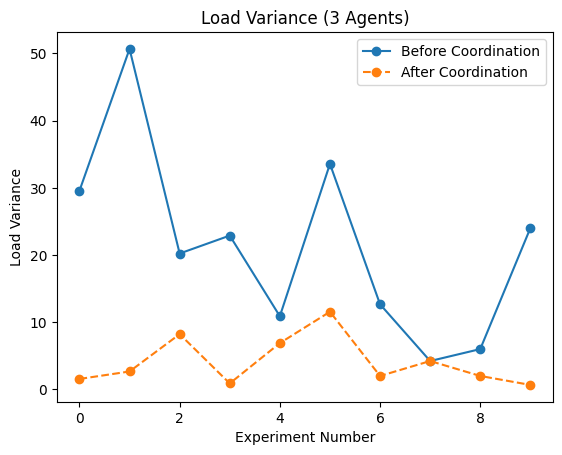

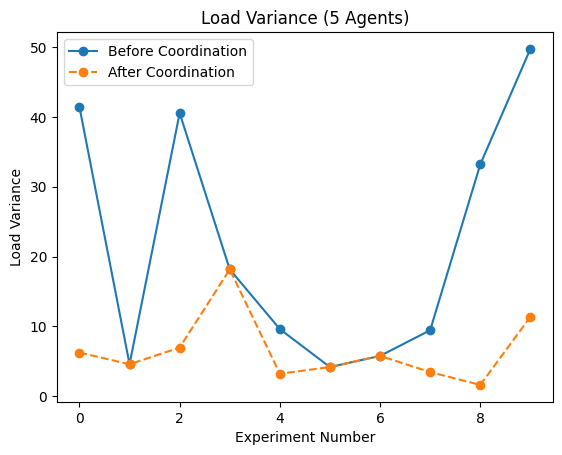

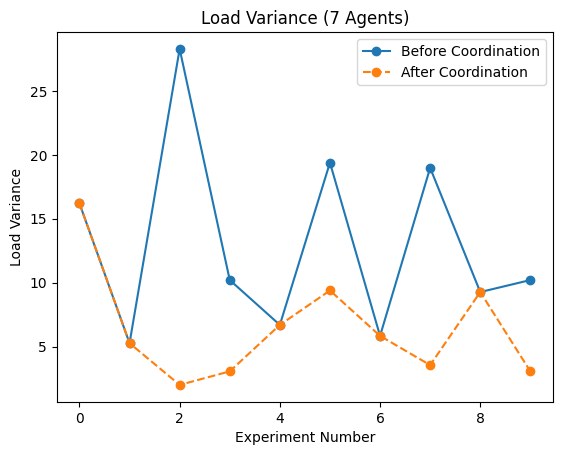

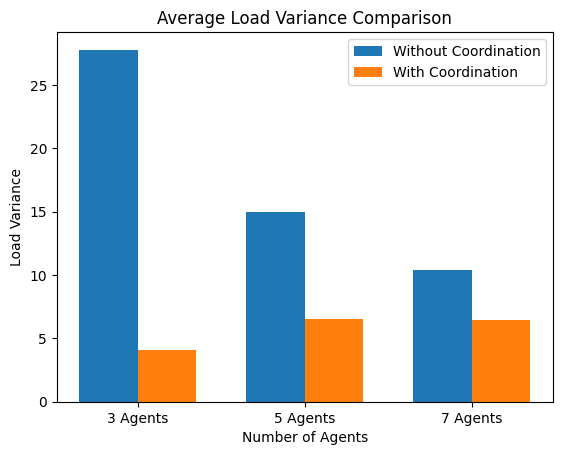

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Classes (System Entities)
# -----------------------------
class Task:
    def __init__(self, difficulty):
        self.difficulty = difficulty  # Task complexity level

class Agent:
    def __init__(self, capacity):
        self.capacity = capacity  # Maximum load the agent can handle
        self.tasks = []

    def load(self):
        return sum(t.difficulty for t in self.tasks)  # Current load

    def can_accept(self, task):
        return self.load() + task.difficulty <= self.capacity  # Capacity constraint


# -----------------------------
# Performance Metric
# -----------------------------
def load_variance(agents):
    loads = [a.load() for a in agents]
    return np.var(loads)  # Measures load imbalance


# -----------------------------
# Simulation WITH Coordination
# -----------------------------
def run_simulation(num_agents=3, num_tasks=10, max_iterations=10):

    # Initialize agents and tasks
    agents = [Agent(random.randint(8,15)) for _ in range(num_agents)]
    tasks = [Task(random.randint(1,5)) for _ in range(num_tasks)]

    # Random task distribution
    for t in tasks:
        random.choice(agents).tasks.append(t)

    before = load_variance(agents)  # Initial imbalance
    message_count = 0  # Communication metric

    # -----------------------------
    # Iterative Coordination Process
    # -----------------------------
    for _ in range(max_iterations):  # Coordination loop

        improved = False

        for agent in agents:
            if agent.load() > agent.capacity:

                task = agent.tasks.pop()

                # -----------------------------
                # Communication + Negotiation
                # -----------------------------
                candidates = []
                for other in agents:
                    if other != agent:

                        message_count += 1  # Communication between agents

                        if other.can_accept(task):
                            cost = other.load()
                            candidates.append((other, cost))

                # -----------------------------
                # Negotiation Decision
                # -----------------------------
                if candidates:
                    best_agent = min(candidates, key=lambda x: x[1])[0]
                    # Select agent with minimum load

                    best_agent.tasks.append(task)
                    # Cooperation: task transfer

                    improved = True
                else:
                    agent.tasks.append(task)  # No valid transfer

        if not improved:
            break  # Stop if no improvement

    after = load_variance(agents)  # Final imbalance

    return before, after, message_count


# -----------------------------
# Simulation WITHOUT Coordination
# -----------------------------
def run_without_coordination(num_agents=3, num_tasks=10):

    agents = [Agent(random.randint(8,15)) for _ in range(num_agents)]
    tasks = [Task(random.randint(1,5)) for _ in range(num_tasks)]

    for t in tasks:
        random.choice(agents).tasks.append(t)

    return load_variance(agents)


# -----------------------------
# Experiments Setup
# -----------------------------
agent_sizes = [3, 5, 7]
# Evaluate scalability under different system sizes

num_runs = 10  # Number of experiments

results = {}

for n_agents in agent_sizes:

    before_vals = []
    after_vals = []
    msg_vals = []
    no_coord_vals = []

    for _ in range(num_runs):
        # Multiple experiments for statistical reliability

        b, a, m = run_simulation(num_agents=n_agents)

        before_vals.append(b)
        after_vals.append(a)
        msg_vals.append(m)

        no_coord_vals.append(run_without_coordination(num_agents=n_agents))

    results[n_agents] = {
        "before": before_vals,
        "after": after_vals,
        "before_avg": np.mean(before_vals),
        "after_avg": np.mean(after_vals),
        "messages_avg": np.mean(msg_vals),
        "no_coord_avg": np.mean(no_coord_vals)
    }


# -----------------------------
# Display Results
# -----------------------------
print("===== FINAL RESULTS =====\n")

for n_agents, data in results.items():
    print(f"Agents: {n_agents}")
    print(f"  WITHOUT Coordination: {data['no_coord_avg']:.2f}")
    print(f"  WITH Coordination:    {data['after_avg']:.2f}")
    print(f"  Messages (avg):       {data['messages_avg']:.2f}")
    print("-" * 30)


# -----------------------------
# Visualization (Line Charts)
# -----------------------------
for n_agents in agent_sizes:
    plt.figure()

    plt.plot(results[n_agents]["before"], marker='o', label='Before Coordination')
    plt.plot(results[n_agents]["after"], marker='o', linestyle='--', label='After Coordination')

    plt.title(f'Load Variance ({n_agents} Agents)')
    plt.xlabel('Experiment Number')
    plt.ylabel('Load Variance')
    plt.legend()

    plt.show()


# -----------------------------
# Summary Visualization (Bar Chart)
# -----------------------------
labels = [f"{n} Agents" for n in agent_sizes]

before_avgs = [results[n]["no_coord_avg"] for n in agent_sizes]
after_avgs = [results[n]["after_avg"] for n in agent_sizes]

x = np.arange(len(labels))
width = 0.35

plt.figure()

plt.bar(x - width/2, before_avgs, width, label='Without Coordination')
plt.bar(x + width/2, after_avgs, width, label='With Coordination')

plt.xticks(x, labels)
plt.title("Average Load Variance Comparison")
plt.xlabel("Number of Agents")
plt.ylabel("Load Variance")
plt.legend()

plt.show()